### Regularization is a machine learning technique that prevents models from overfitting by adding a penalty to the model's complexity.


## Why Do We Need Regularization?

When a model trains on data, its ultimate goal is to minimize its error (Loss Function). However, real-world data contains both the true underlying pattern and random noise (imperfections, errors, anomalies).

• The Problem: Highly complex models (like deep decision trees or high-degree polynomials) are too good at learning. They capture the noise along with the pattern. They get 100% accuracy on training data but fail completely on validation data.

• The Solution: Regularization changes the rules of the game. Instead of telling the model, "Find the line with the absolute lowest error," regularization tells the model, "Find the line with the lowest error AND keep the mathematical weights of your features as small as possible."

By penalizing massive weights, the model is mathematically discouraged from creating chaotic, wiggly lines, forcing it to generalize well to new, unseen data.


### How It Works Mathematically (The Intuition)

In a standard linear regression model, the algorithm calculates predictions using a mathematical equation:

\(\^{y}=w_{1}(X_{1})+w_{2}(X_{2})+b\)

Where w represents the weights (coefficients/importance) given to each feature. If a model overfits, it starts assigning massive, explosive values to these weights (e.g., w₁ = 5,000, w₂ = -8,500) just to force the curve through a few noisy outlier data points.

Regularization modifies the cost function by adding a penalty term:

#### New Cost Function = standard Training Error (MSE)+Penalty for Large Weights

If the model tries to spike its weights up to fit an outlier, the Penalty term explodes, causing the overall cost to shoot up. To keep the cost low, the model is forced to keep its lines smooth and balanced.

## Ridge Regression (L2 Regularization)
Ridge adds the squared coefficients to the objective:
\[
J(w)=MSE+\alpha\sum_{j=1}^{p}w_j^2
\]
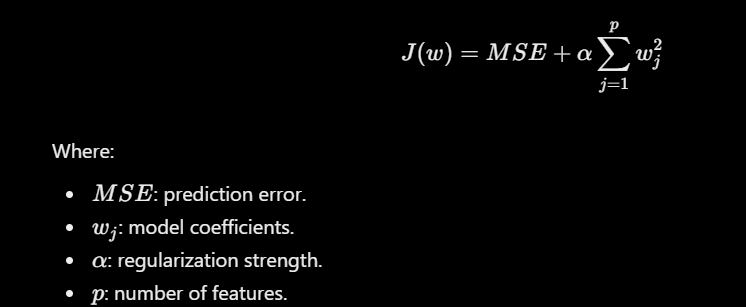

How it works:
- Shrinks coefficients toward zero.
- Usually does not make coefficients exactly zero.
- Helps control model complexity.
- Can be useful when features are correlated.
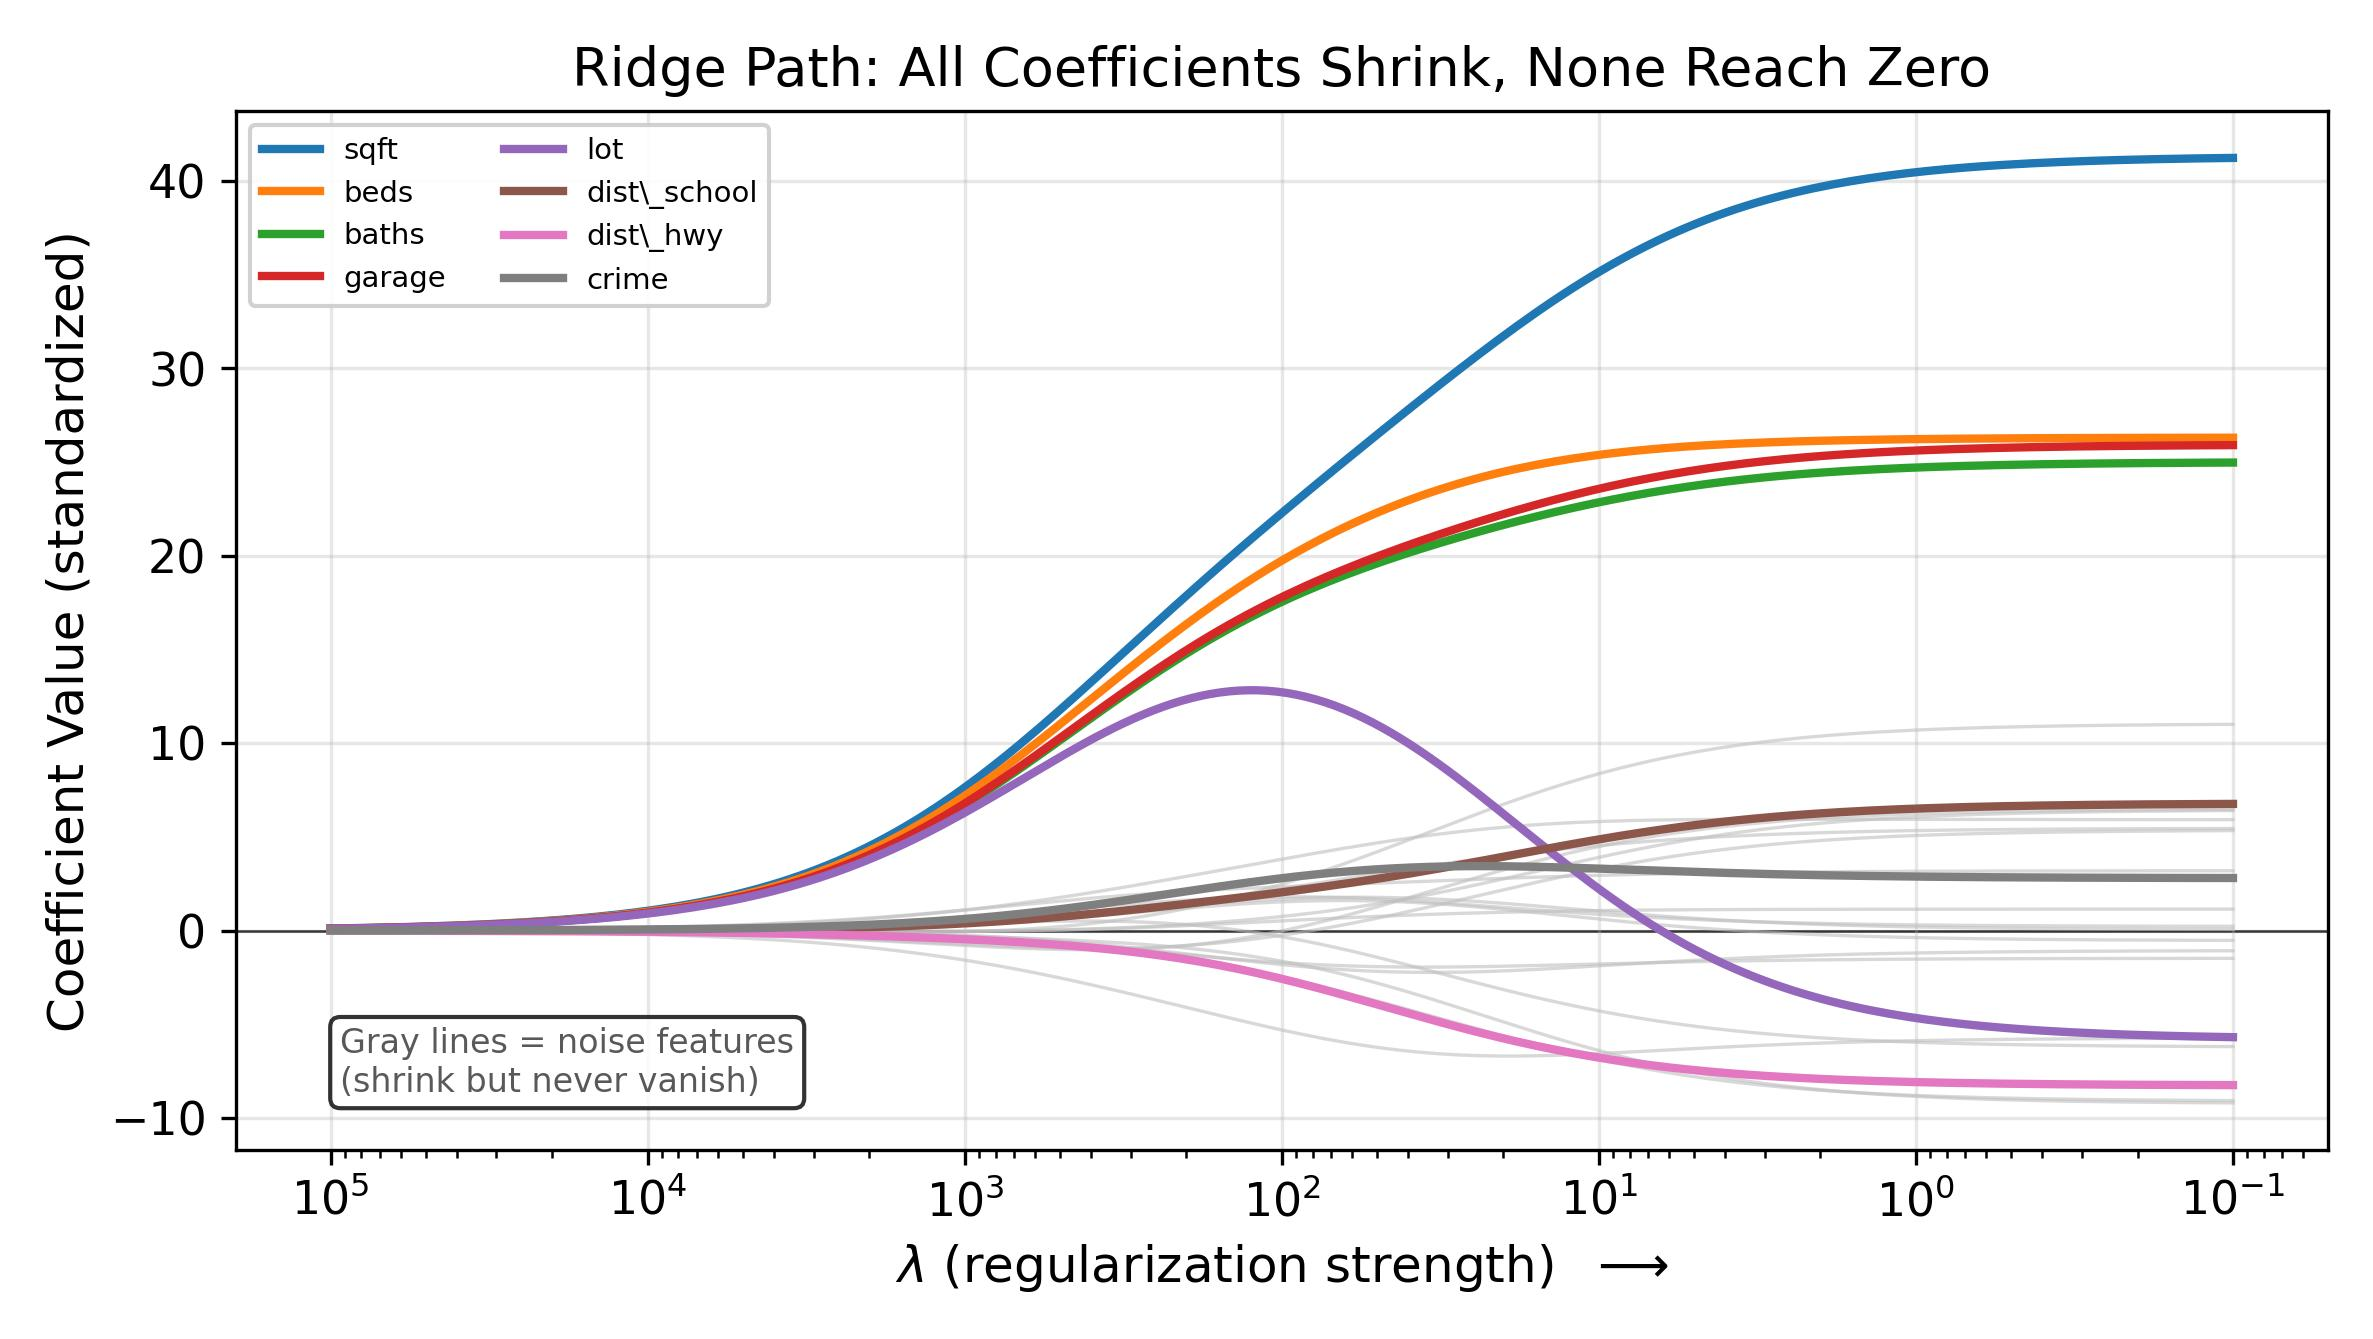

## Lasso Regression (L1 Regularization)

Lasso adds the absolute values of coefficients:

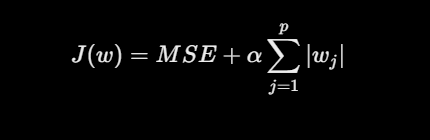

How it works:
- Shrinks coefficients.
- Can make some coefficients exactly zero.
- Performs a form of feature selection.
- Can produce simpler models.

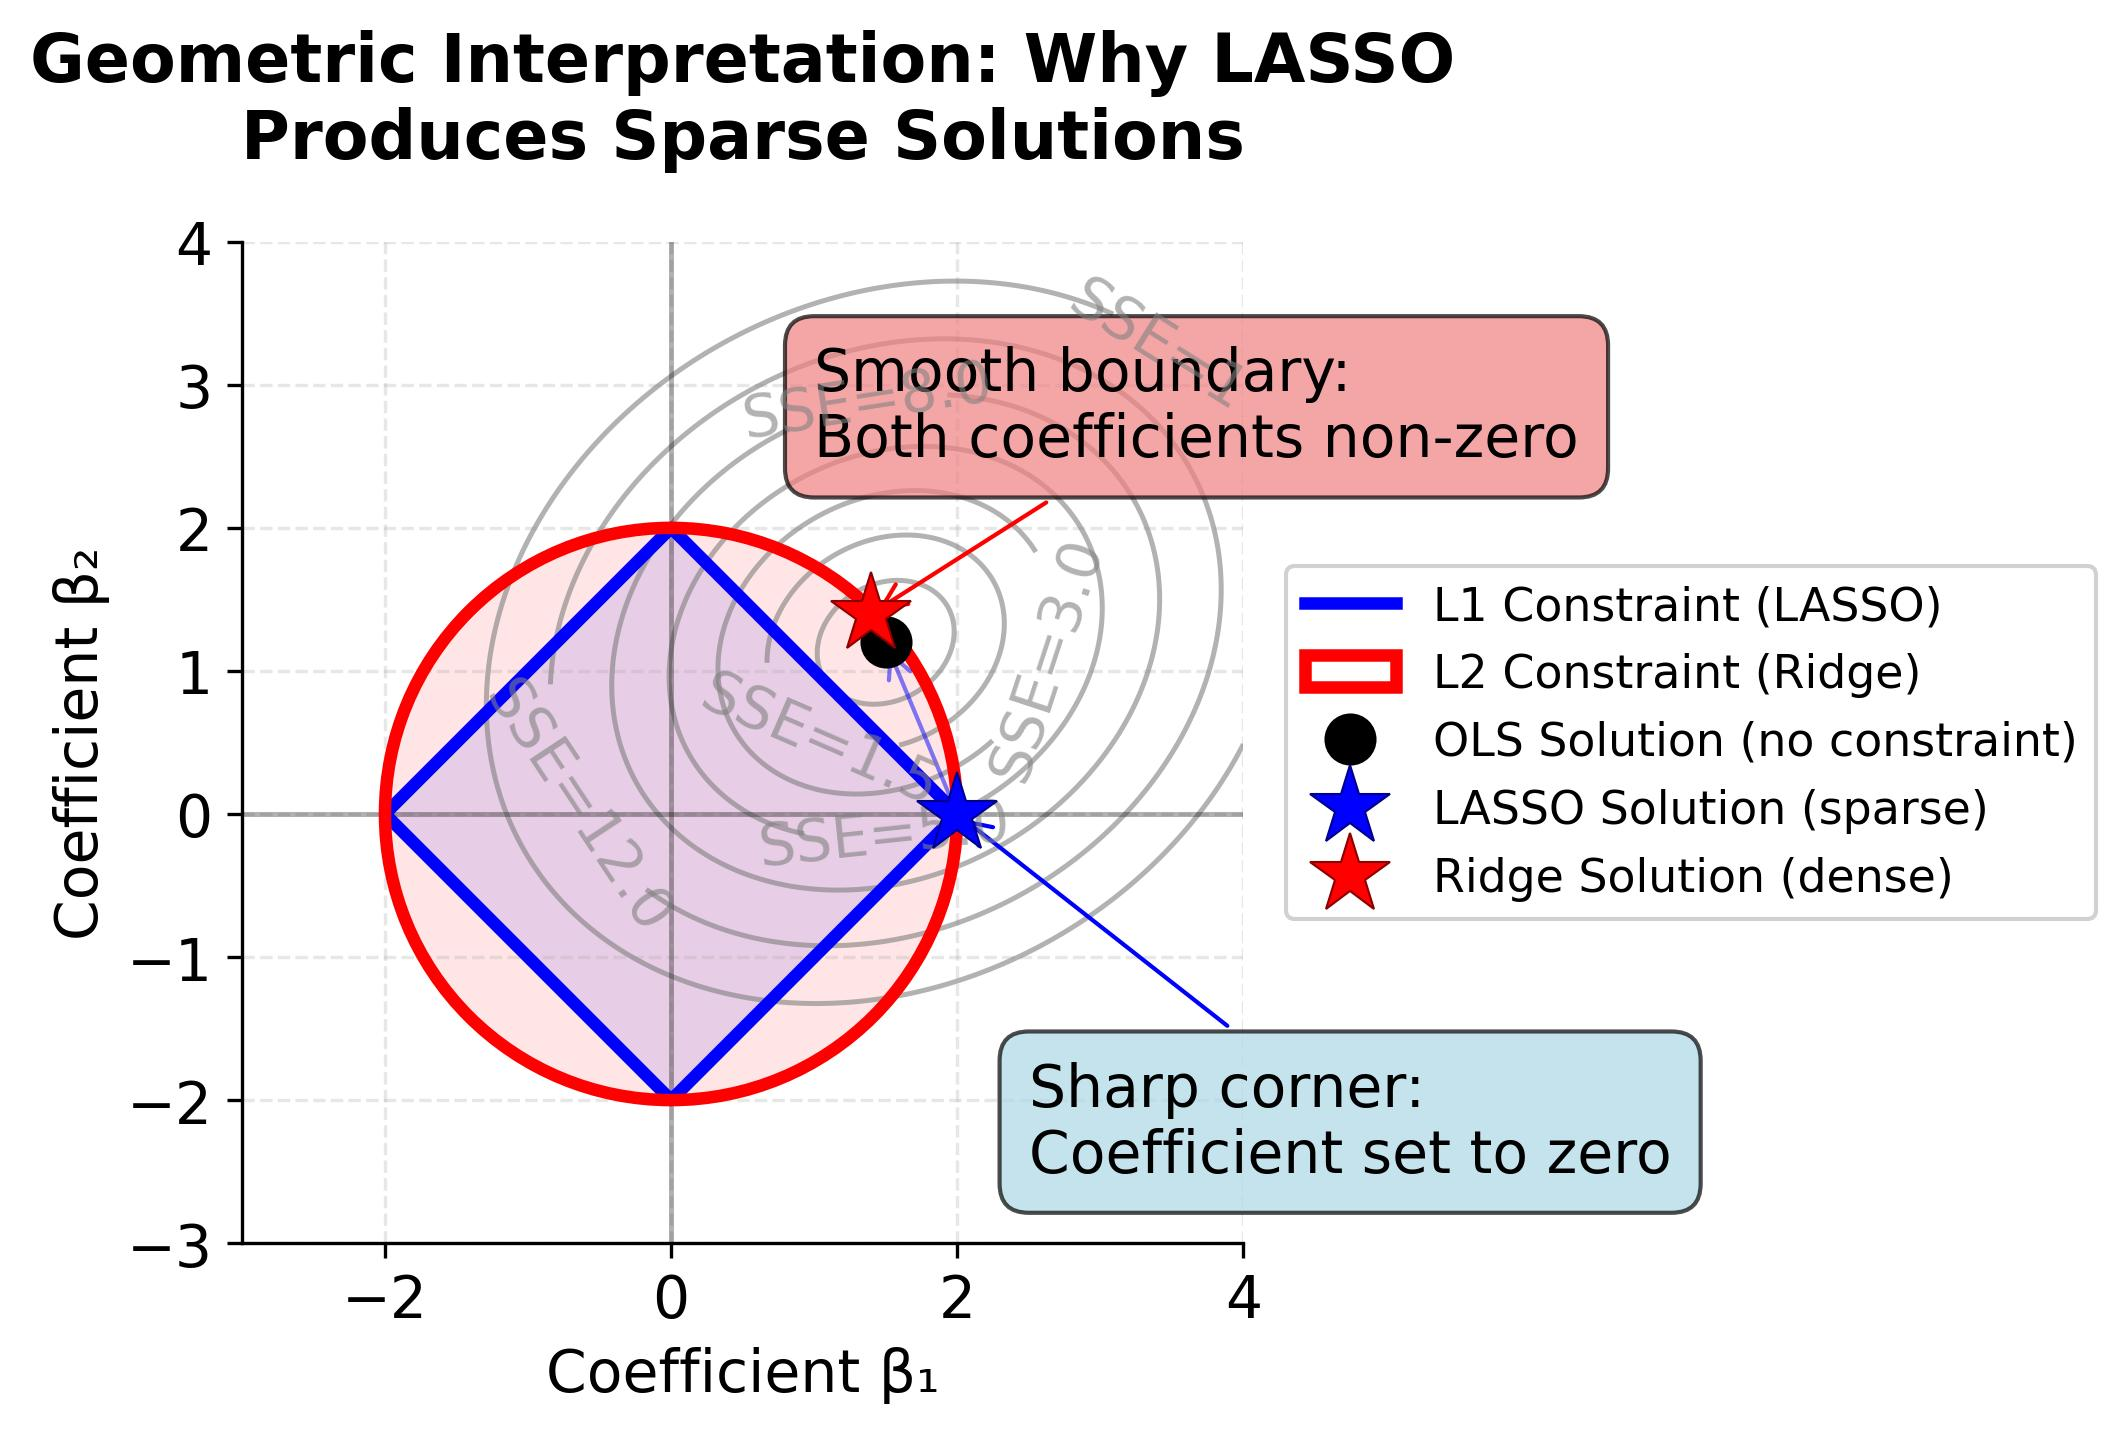

## Elastic Net
### Elastic Net combines Ridge and Lasso penalties.

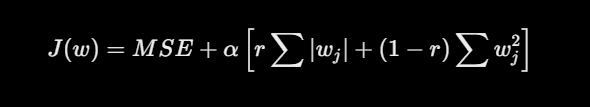


Where \(r\) controls the mixture of L1 and L2 penalties.

In scikit-learn, this mixture is called l1_ratio.
- l1_ratio=1: Lasso-like penalty.
- l1_ratio=0: Ridge-like penalty.
- Between 0 and 1: combination of both.
Elastic Net can be useful when you have many correlated features and want some feature selection.

In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

X, y = make_regression(
    n_samples=300,
    n_features=20,
    n_informative=8,
    noise=20,
    random_state=42
)

feature_names = [f"Feature_{i+1}" for i in range(X.shape[1])]

df = pd.DataFrame(X, columns=feature_names)
df["Target"] = y

df.head()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,...,Feature_12,Feature_13,Feature_14,Feature_15,Feature_16,Feature_17,Feature_18,Feature_19,Feature_20,Target
0,-0.272545,0.500143,-0.844324,-2.230468,0.695864,-0.900590,-0.340599,0.945870,-1.781158,-1.132785,...,0.102485,1.173442,-0.482828,1.369701,-0.553090,1.255404,0.226684,0.350370,-1.086055,-88.739460
1,0.186609,0.194090,0.746254,0.219150,0.279022,0.191099,-0.446434,1.278452,-0.307778,0.046437,...,0.645484,0.607897,2.163255,0.368673,-0.095296,0.028745,0.249384,-1.359856,-0.393339,64.136702
2,2.918174,-1.130179,-0.211384,-0.852225,-0.010867,0.907962,-0.184146,-0.407460,2.275825,0.123480,...,0.746611,0.137352,0.325578,-0.574101,-0.869287,1.033881,0.518102,-0.124286,0.536414,94.167112
3,2.252436,-0.324831,-1.440051,-2.153390,1.009817,-0.173072,0.981765,0.125576,-0.991392,0.015579,...,1.594505,-0.688150,-0.846961,-0.297564,1.642015,-0.150056,-0.638962,-1.096275,1.375707,-95.321003
4,-2.128734,-0.979721,1.590582,-0.340908,-0.165631,-0.964705,0.458168,1.230001,-0.519396,1.628469,...,0.678931,0.078577,-0.136995,0.706079,-0.593811,-1.026369,0.428317,-0.284385,-0.242681,45.237565


In [2]:
X = df.drop(columns="Target")
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (240, 20)
Testing: (60, 20)


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet


models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),

    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    ),

    "Lasso": make_pipeline(
        StandardScaler(),
        Lasso(alpha=10, max_iter=10000)
    ),

    "Elastic Net": make_pipeline(
        StandardScaler(),
        ElasticNet(alpha=10, l1_ratio=0.5, max_iter=10000)
    )
}

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

               Model     MAE     RMSE     R2
0  Linear Regression  16.565   20.118  0.978
1              Ridge  16.242   19.821  0.979
2              Lasso  30.370   37.749  0.923
3        Elastic Net  94.204  118.916  0.233


In [5]:
ridge_model = models["Ridge"]
lasso_model = models["Lasso"]

ridge_coefficients = ridge_model.named_steps["ridge"].coef_
lasso_coefficients = lasso_model.named_steps["lasso"].coef_

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Ridge": ridge_coefficients,
    "Lasso": lasso_coefficients
})

print(coefficient_comparison.round(3))

       Feature   Ridge   Lasso
0    Feature_1   0.848   0.000
1    Feature_2   0.408   0.000
2    Feature_3  42.624  35.990
3    Feature_4  -0.597  -0.000
4    Feature_5   0.885   0.000
5    Feature_6  86.924  78.878
6    Feature_7   1.732   0.000
7    Feature_8  15.646   2.719
8    Feature_9   0.634  -0.000
9   Feature_10  38.897  27.262
10  Feature_11   1.651   0.000
11  Feature_12  -1.676  -0.000
12  Feature_13   0.436   0.000
13  Feature_14   1.313  -0.000
14  Feature_15  29.987  19.759
15  Feature_16  -0.498  -0.000
16  Feature_17  32.009  23.376
17  Feature_18   0.728   0.000
18  Feature_19  23.666  11.403
19  Feature_20  19.655   8.205


In [6]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X_train, y_train)

    print(
        f"Alpha: {alpha:<7} "
        f"Test R2: {model.score(X_test, y_test):.4f}"
    )

Alpha: 0.001   Test R2: 0.9781
Alpha: 0.01    Test R2: 0.9781
Alpha: 0.1     Test R2: 0.9781
Alpha: 1       Test R2: 0.9783
Alpha: 10      Test R2: 0.9787
Alpha: 100     Test R2: 0.8887
